# EDA — Corpus de reseñas de museos del Perú (Etapa 4-M)

Análisis exploratorio de las reseñas de Google Maps extraídas para los **1081 museos** de
`data/lugares/base_museos_peru.csv`.

## Cómo leer este notebook

Tres advertencias de calidad de datos condicionan qué se puede concluir; cada una se repite en
la sección donde aplica:

| # | Advertencia | Consecuencia |
|---|---|---|
| **A** | `review_date` no es un dato de Google: se estima restando `relative_date` a la fecha de extracción | ~81 % de las reseñas solo tiene precisión de **año**. No se grafica por debajo de mes. |
| **B** | ~45 % de las reseñas **no tiene texto** (son solo estrellas) | Los KPI de texto usan su propio denominador, no el total. |
| **C** | La columna `reviews` mide algo distinto de lo que sirve el panel de Google | No usarla como denominador de cobertura. |

Un cuarto punto, sobre el universo mismo: el 71,7 % de los
1081 museos no tiene "museo" en el nombre, y muchas entradas son dudosas como museos. Los
resultados agregados deben leerse con eso presente.


In [1]:
import re
import unicodedata
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 60)

PROJECT_ROOT = Path.cwd().parent


## 1. Carga, join e integridad

Se unen las reseñas con la base de museos para recuperar `categoria_normalizada`, geografía
y las métricas que Google reportaba al momento de la búsqueda.

**Clave de join**: `google_place_id` (reseñas) ↔ `id` (base de museos).


In [2]:
museos  = pd.read_csv(PROJECT_ROOT / "data" / "lugares" / "base_museos_peru.csv")
resenas = pd.read_csv(PROJECT_ROOT / "data" / "resenas" / "comentarios_museos_crudo.csv")

# categoria_google es degenerada (un solo valor "Museo"): la categoria util viene del join.
cols_museo = ["id", "categoria_normalizada", "palabra_clave", "prioridad",
              "stars", "reviews", "lat", "lon", "departamento_final",
              "provincia_final", "distrito_final"]
resenas = resenas.merge(
    museos[cols_museo].rename(columns={"id": "google_place_id"}),
    on="google_place_id", how="left",
)

print(f"Museos en el universo:                    {len(museos):,}")
print(f"Reseñas extraídas:                        {len(resenas):,}")
print(f"Museos con al menos una reseña:           {resenas['google_place_id'].nunique():,}")
print(f"Avance de la extracción:                  {100*resenas['google_place_id'].nunique()/len(museos):.1f}%")
print(f"Reseñas sin match en la base de museos:   {resenas['categoria_normalizada'].isna().sum():,}")


Museos en el universo:                    1,081
Reseñas extraídas:                        38,693
Museos con al menos una reseña:           784
Avance de la extracción:                  72.5%
Reseñas sin match en la base de museos:   0


In [3]:
print("--- Nulos en las reseñas ---")
nulos = resenas.isnull().sum()
print(nulos[nulos > 0].to_string())
print()
print(f"Duplicados por id_review: {resenas['id_review'].duplicated().sum()}")
print(f"Duplicados por (museo, id_review): {resenas.duplicated(['google_place_id','id_review']).sum()}")
print()
print(f"Rango de fechas estimadas: {resenas['review_date'].min()} .. {resenas['review_date'].max()}")


--- Nulos en las reseñas ---
caption    18525
stars        493
reviews       56

Duplicados por id_review: 423
Duplicados por (museo, id_review): 0

Rango de fechas estimadas: 2013-09-02 19:52:34.918560 .. 2026-08-31 21:14:39.740074


## 2. El universo de museos

Distribución del universo completo (1081), independiente de cuántas reseñas se hayan
extraído. Se usa `categoria_normalizada` —la taxonomía del proyecto— y no `categoria_google`,
que tiene un único valor y no discrimina nada.


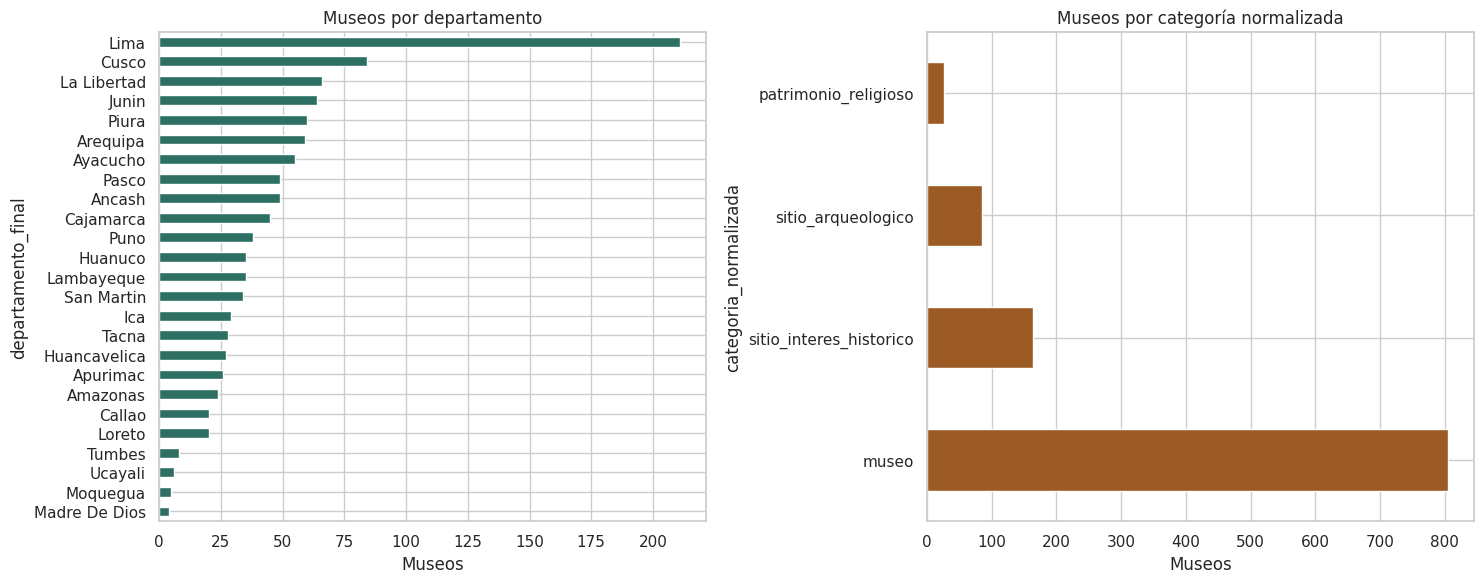

categoria_normalizada
museo                      805
sitio_interes_historico    164
sitio_arqueologico          85
patrimonio_religioso        27


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

museos["departamento_final"].value_counts().sort_values().plot(
    kind="barh", ax=axes[0], color="#2E6F63")
axes[0].set_title("Museos por departamento")
axes[0].set_xlabel("Museos")

museos["categoria_normalizada"].value_counts().plot(
    kind="barh", ax=axes[1], color="#9C5A24")
axes[1].set_title("Museos por categoría normalizada")
axes[1].set_xlabel("Museos")

plt.tight_layout(); plt.show()

print(museos["categoria_normalizada"].value_counts().to_string())


In [5]:
# Señal de calidad del universo
def sin_tildes(s):
    return "".join(c for c in unicodedata.normalize("NFKD", str(s))
                   if not unicodedata.combining(c)).upper()

museos["museo_en_titulo"] = museos["title"].map(
    lambda t: bool(re.search(r"MUSE(O|UM)", sin_tildes(t))))

resumen = museos.groupby("museo_en_titulo")["reviews"].agg(
    museos="size", mediana_resenas="median", pct_hasta_10=lambda s: 100*(s <= 10).mean())
resumen.index = ["Sin 'museo' en el título", "Con 'museo' en el título"]
print(resumen.round(1).to_string())
print()
print("Los que no llevan 'museo' en el nombre tienen sistemáticamente menos reseñas.")


                          museos  mediana_resenas  pct_hasta_10
Sin 'museo' en el título     775              9.0          45.8
Con 'museo' en el título     306             36.0          30.1

Los que no llevan 'museo' en el nombre tienen sistemáticamente menos reseñas.


## 3. Calificaciones

`rating` es una métrica semi-aditiva: el promedio correcto es `SUM(rating)/COUNT(*)`.
Promediar promedios por museo daría un número distinto y equivocado.


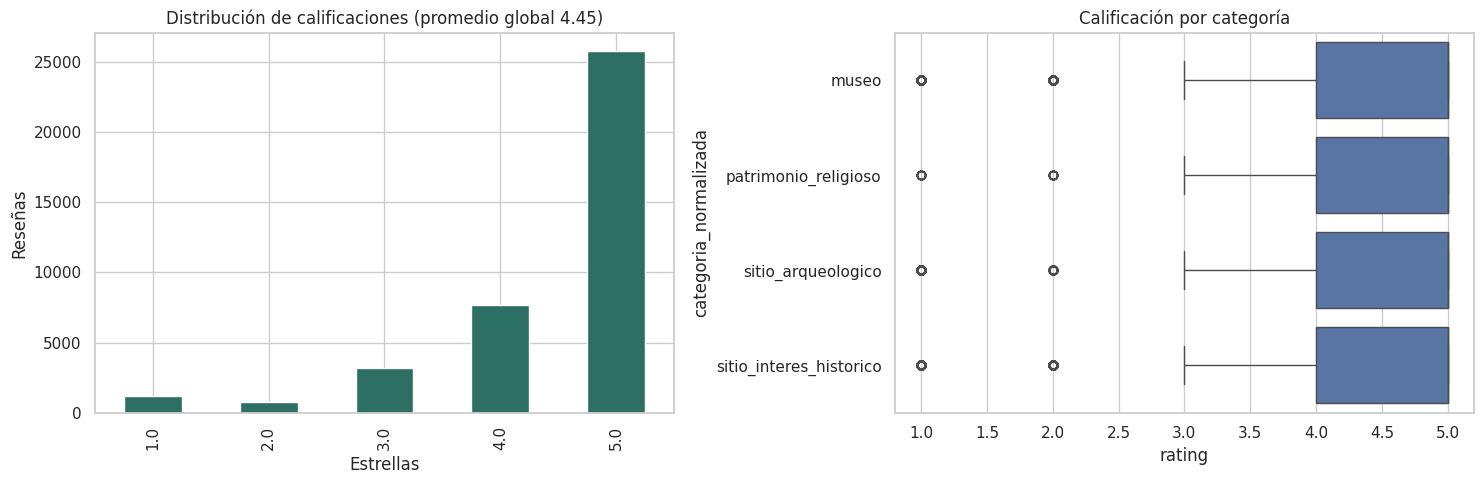

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

resenas["rating"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0], color="#2E6F63")
axes[0].set_title(f"Distribución de calificaciones (promedio global {resenas['rating'].mean():.2f})")
axes[0].set_xlabel("Estrellas"); axes[0].set_ylabel("Reseñas")

orden = resenas.groupby("categoria_normalizada")["rating"].median().sort_values().index
sns.boxplot(data=resenas, y="categoria_normalizada", x="rating", order=orden, ax=axes[1])
axes[1].set_title("Calificación por categoría")

plt.tight_layout(); plt.show()


In [7]:
top = (resenas.groupby(["google_place_id", "nombre_lugar"])
       .agg(n_resenas=("rating", "size"), rating_promedio=("rating", "mean"))
       .sort_values("n_resenas", ascending=False))
print("=== 15 museos con más reseñas extraídas ===")
print(top.head(15).round(2).to_string())


=== 15 museos con más reseñas extraídas ===
                                                                      n_resenas  rating_promedio
google_place_id             nombre_lugar                                                        
ChIJJT73zArWbZERPWclxK0YkWk Qorikancha                                     1850             4.73
ChIJBZ9VaEs8rZERR4TLfIIb6zI Museo de Sitio Chan Chan                       1160             4.52
ChIJXQUpiPTJBZER3BGAQvjZqqE Museo del Café Peruano                         1048             4.87
ChIJ69AwCnTWbZERLlBKCuxa7mc Museo Histórico Regional de Cusco              1040             4.38
ChIJqe8B2MHIBZERTjl0df57wxE Museo Metropolitano de Lima                    1020             4.59
ChIJK6X3hJK3BZERPyqDqUce6p8 Museo Pedro de Osma                             920             4.60
ChIJkSRI8bbIBZER9rW9dZO6W2A Museo Central - MUCEN                           800             4.76
ChIJa82gbs7IBZERyOAn0bKUS4o Museo Nacional de la Cultura Peruana            780    

## 4. Precisión temporal — leer antes de cualquier serie de tiempo

Google **no publica** la fecha en que se escribió una reseña: solo una etiqueta relativa
("Hace 6 meses"). El scraper deriva `review_date` restando esa etiqueta al momento de
extracción, con mes = 30 días y año = 365 días.

Por eso `review_date` tiene apariencia de precisión (llega a microsegundos) que **no
corresponde a la realidad**. Esta sección mide cuánta precisión hay de verdad.


=== Precisión REAL de la fecha de reseña ===
                 reseñas     %
precision_fecha               
AÑO                31231  80.7
MES                 6628  17.1
SEMANA               677   1.7
DIA                  157   0.4

El 80.7% de las reseñas solo puede ubicarse dentro de un año.
  Por eso abajo no se grafica ninguna serie por debajo de granularidad mensual:
  una curva diaria o semanal sería ruido inventado con apariencia de dato.


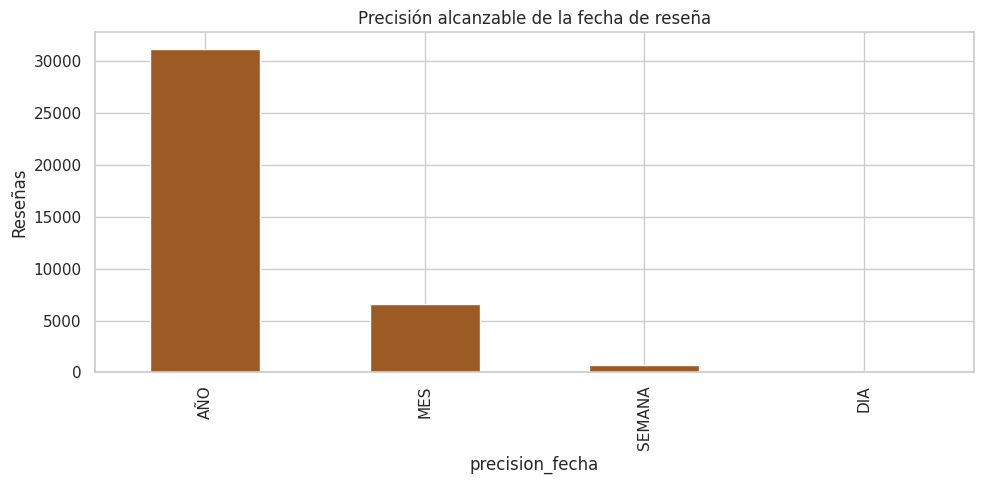

In [8]:
def precision_de(rel):
    s = str(rel).lower()
    if "segundo" in s or "minuto" in s or "hora" in s or "día" in s or "dia" in s:
        return "DIA"
    if "semana" in s:
        return "SEMANA"
    if "mes" in s:
        return "MES"
    if "año" in s or "ano" in s:
        return "AÑO"
    return "NA"

resenas["precision_fecha"] = resenas["relative_date"].map(precision_de)
dist = resenas["precision_fecha"].value_counts()
pct = (100 * dist / len(resenas)).round(1)

print("=== Precisión REAL de la fecha de reseña ===")
print(pd.DataFrame({"reseñas": dist, "%": pct}).to_string())
print()
print(f"El {pct.get('AÑO', 0)}% de las reseñas solo puede ubicarse dentro de un año.")
print("  Por eso abajo no se grafica ninguna serie por debajo de granularidad mensual:")
print("  una curva diaria o semanal sería ruido inventado con apariencia de dato.")

dist.plot(kind="bar", color="#9C5A24")
plt.title("Precisión alcanzable de la fecha de reseña"); plt.ylabel("Reseñas")
plt.tight_layout(); plt.show()


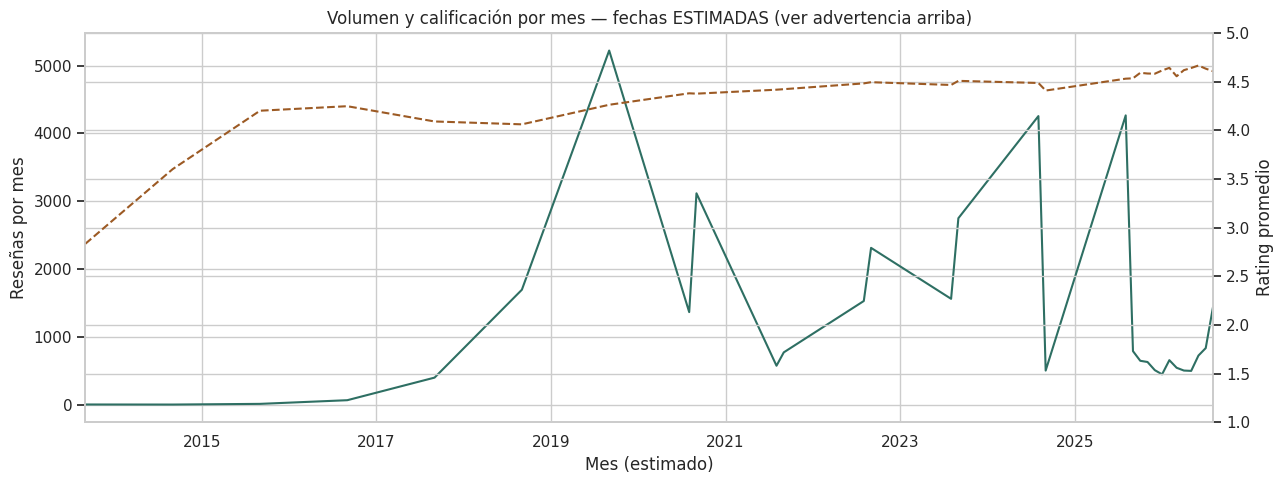

In [9]:
# Serie MENSUAL — el grano mínimo defendible dado lo anterior
resenas["mes"] = pd.to_datetime(resenas["review_date"], errors="coerce").dt.to_period("M")
serie = resenas.groupby("mes").agg(n_resenas=("rating", "size"),
                                   rating_promedio=("rating", "mean"))
serie = serie[serie.index.notna()].tail(48)

fig, ax1 = plt.subplots(figsize=(13, 5))
serie["n_resenas"].plot(ax=ax1, color="#2E6F63", label="Reseñas")
ax1.set_ylabel("Reseñas por mes"); ax1.set_xlabel("Mes (estimado)")
ax2 = ax1.twinx()
serie["rating_promedio"].plot(ax=ax2, color="#9C5A24", linestyle="--", label="Rating")
ax2.set_ylabel("Rating promedio"); ax2.set_ylim(1, 5)
plt.title("Volumen y calificación por mes — fechas ESTIMADAS (ver advertencia arriba)")
plt.tight_layout(); plt.show()


## 5. Cobertura de extracción — con el denominador correcto

Hay **dos conteos distintos** de reseñas y no miden lo mismo:

- `reviews` (columna de la base) viene del **listado de búsqueda** de la Etapa 2.
- Lo que el **panel del lugar** sirve es bastante menos, y es el 100 % de lo que el scraper
  logra extraer.

Verificado: donde la base dice 118, el panel declara 29 y se extraen las 29. Usar `reviews`
como denominador da una cobertura falsamente catastrófica.

Requiere haber corrido antes:
`python3 repos_wrapper/scrape_comentarios_museos.py --consolidate-only`


In [10]:
ruta_cob = PROJECT_ROOT / "data" / "resenas" / "cobertura_museos_por_lugar.csv"
if not ruta_cob.exists():
    print("Falta cobertura_museos_por_lugar.csv — correr primero --consolidate-only.")
else:
    cob = pd.read_csv(ruta_cob)
    print("=== Estado de la extracción ===")
    print(cob["status"].value_counts().to_string())
    print()
    print(f"Reseñas extraídas en total:        {int(cob['n_reviews_obtenidas_real'].sum()):,}")
    print(f"Museos con al menos una reseña:    {int((cob['n_reviews_obtenidas_real'] > 0).sum()):,}")
    print()
    sosp = cob[cob["sospechoso_cero_resenas"]]
    if len(sosp):
        print(f"{len(sosp)} museos marcados 'completado' con 0 reseñas extraídas.")
        print("  No se reintentan solos (get_pending ignora 'completado').")
        print(sosp.nlargest(8, "n_reviews_google")[["nombre", "n_reviews_google"]].to_string(index=False))


=== Estado de la extracción ===
status
completado    784
fallido       297

Reseñas extraídas en total:        38,693
Museos con al menos una reseña:    784



              museos  resenas
departamento                 
Lima             211    14091
Cusco             84     4972
La Libertad       66     4563
Arequipa          59     2140
Huanuco           35     1469
Ayacucho          55     1412
Loreto            20     1168
Puno              38     1139
Piura             60     1123
San Martin        34      795
Pasco             49      776
Cajamarca         45      757
Tacna             28      743
Junin             64      742
Ica               29      632


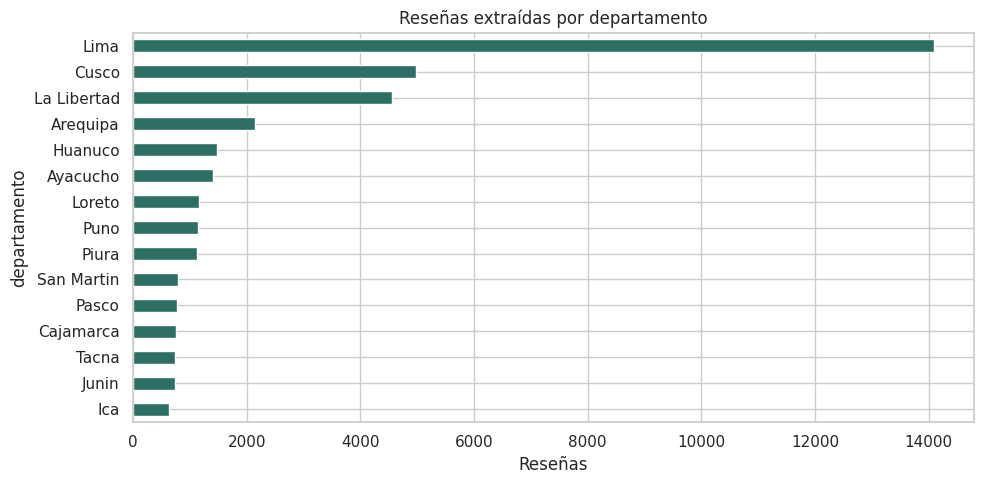

In [11]:
if ruta_cob.exists():
    por_depto = (cob.groupby("departamento")
                 .agg(museos=("lugar_id", "size"),
                      resenas=("n_reviews_obtenidas_real", "sum"))
                 .sort_values("resenas", ascending=False))
    print(por_depto.head(15).to_string())

    por_depto["resenas"].head(15).sort_values().plot(kind="barh", color="#2E6F63")
    plt.title("Reseñas extraídas por departamento"); plt.xlabel("Reseñas")
    plt.tight_layout(); plt.show()


## 6. Análisis de texto — con su propio denominador

Cerca del **45 % de las reseñas no tiene texto**: son calificaciones de solo estrellas. El
universo del análisis cuantitativo y el del análisis textual son poblaciones distintas.

Todo lo que sigue se calcula **solo sobre las reseñas con texto**, y ese denominador se
declara explícitamente en cada resultado.


In [12]:
con_texto = resenas[resenas["caption"].notna()].copy()
pct_texto = 100 * len(con_texto) / len(resenas)

print(f"Reseñas totales:      {len(resenas):,}")
print(f"Reseñas CON texto:    {len(con_texto):,}  ({pct_texto:.1f}%)")
print(f"Reseñas SIN texto:    {len(resenas) - len(con_texto):,}  ({100-pct_texto:.1f}%)")
print()
print("Todo lo que sigue usa el denominador de reseñas CON texto, no el total.")

con_texto["n_palabras"] = con_texto["caption"].str.split().str.len()
print()
print(con_texto["n_palabras"].describe().round(1).to_string())


Reseñas totales:      38,693
Reseñas CON texto:    20,168  (52.1%)
Reseñas SIN texto:    18,525  (47.9%)

Todo lo que sigue usa el denominador de reseñas CON texto, no el total.

count    20168.0
mean        17.6
std         25.4
min          1.0
25%          4.0
50%         11.0
75%         23.0
max        679.0


=== 20 palabras más frecuentes (sobre 20,168 reseñas con texto) ===
  museo                3930
  historia             2365
  excelente            2038
  interesante          1847
  bonito               1662
  experiencia          1276
  hermoso              1160
  guia                 1070
  buena                1058
  visitar              1041
  cultura              1011
  entrada               982
  buen                  968
  conocer               964
  visita                956
  atencion              878
  peru                  789
  cafe                  778
  pequeno               771
  casa                  715


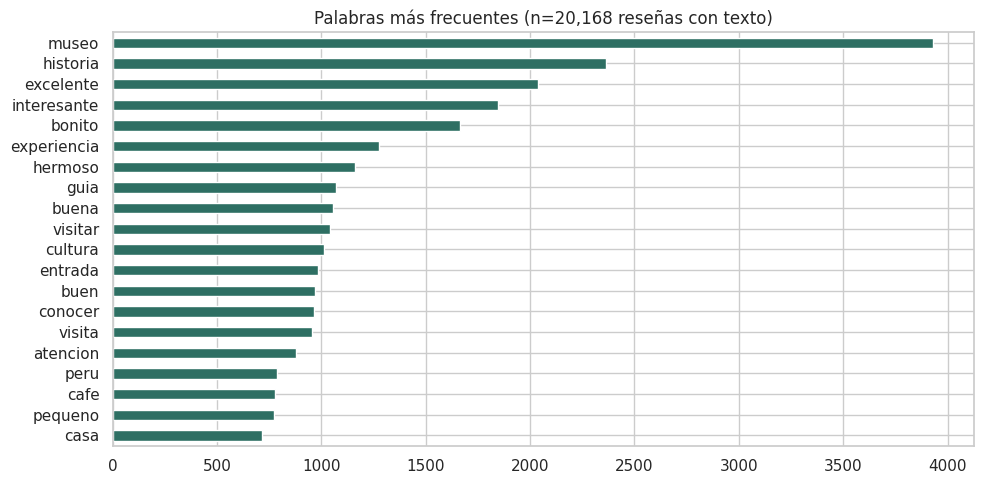

In [13]:
STOPWORDS = set("""
a al algo algunas algunos ante antes como con contra cual cuando de del desde donde dos el
ella ellas ellos en entre era eran es esa ese eso esta estan este esto estos fue fueron ha
hasta hay la las le les lo los mas me mi mucho muy no nos o os otra otro para pero poco por
porque que quien se ser si sin sobre solo son su sus tambien tanto te tiene todo todos tu un
una uno unos y ya lugar puede hace bien alli ahi asi mismo cada tan
""".split())

def tokenizar(texto):
    t = "".join(c for c in unicodedata.normalize("NFKD", str(texto).lower())
                if not unicodedata.combining(c))
    return [w for w in re.findall(r"[a-zñ]{3,}", t) if w not in STOPWORDS]

tokens = con_texto["caption"].map(tokenizar)
frec = Counter(w for lista in tokens for w in lista)

print(f"=== 20 palabras más frecuentes (sobre {len(con_texto):,} reseñas con texto) ===")
for palabra, n in frec.most_common(20):
    print(f"  {palabra:<18} {n:>6}")

pd.Series(dict(frec.most_common(20))).sort_values().plot(kind="barh", color="#2E6F63")
plt.title(f"Palabras más frecuentes (n={len(con_texto):,} reseñas con texto)")
plt.tight_layout(); plt.show()


In [14]:
# Vocabulario diferencial: qué distingue a las reseñas positivas de las negativas
alta = con_texto[con_texto["rating"] >= 4]["caption"].map(tokenizar)
baja = con_texto[con_texto["rating"] <= 2]["caption"].map(tokenizar)

f_alta = Counter(w for l in alta for w in l)
f_baja = Counter(w for l in baja for w in l)
n_alta = max(sum(f_alta.values()), 1)
n_baja = max(sum(f_baja.values()), 1)

print(f"Reseñas con texto y rating >=4: {len(alta):,}")
print(f"Reseñas con texto y rating <=2: {len(baja):,}")
print()

# frecuencia relativa: evita que las palabras comunes dominen ambas listas
distintivas_baja = sorted(
    ((w, f_baja[w]/n_baja - f_alta.get(w, 0)/n_alta, f_baja[w])
     for w in f_baja if f_baja[w] >= 5),
    key=lambda x: -x[1])[:15]

print("=== Palabras más distintivas de las reseñas NEGATIVAS ===")
for w, dif, n in distintivas_baja:
    print(f"  {w:<18} {n:>5} apariciones")


Reseñas con texto y rating >=4: 17,505
Reseñas con texto y rating <=2: 1,125

=== Palabras más distintivas de las reseñas NEGATIVAS ===
  cerrado              167 apariciones
  nada                  92 apariciones
  estaba                98 apariciones
  mal                   63 apariciones
  horario               57 apariciones
  habia                 64 apariciones
  abierto               51 apariciones
  entrar                52 apariciones
  falta                 49 apariciones
  mala                  35 apariciones
  soles                 78 apariciones
  dice                  34 apariciones
  ver                   77 apariciones
  atencion              96 apariciones
  pesima                30 apariciones


## 7. Síntesis

Al interpretar cualquier resultado de arriba, tener presente:

1. **Las fechas son estimadas** (A) — no hay conclusiones válidas sobre estacionalidad fina.
2. **Los KPI de texto cubren ~55 % del corpus** (B).
3. **La cobertura se mide contra el panel**, no contra la columna `reviews` (C).
4. **El universo tiene ruido conocido**: 71,7 % de los museos no lleva "museo" en el nombre.
   Conviene repetir los cortes principales restringiendo a
   los museos de confianza alta antes de publicar conclusiones.
